<a href="https://colab.research.google.com/github/asala-ai/AgriRecover-Gaza/blob/main/AgriRecover_Deep_Learning_Project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# AgriRecover Gaza
## Deep Learning for Agricultural Vegetation Prediction

**Project Type:** Deep Learning Course Project

**Study Area:** Gaza Strip, Palestine

### Project Overview
This project uses Sentinel-2 satellite data and deep learning techniques to analyze agricultural vegetation changes in the Gaza Strip.

### Project Objective
To develop a deep learning model that predicts future agricultural vegetation conditions using historical spectral indices.

### Dataset
- 500 agricultural sample points.
- 105 monthly observations.
- Six spectral indices: NDVI, EVI, NDMI, SAVI, BSI, and NBR.

**Data Period:** January 2018 – September 2026.

In [ ]:

# Import Required Libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

print("Libraries imported successfully!")
print("TensorFlow Version:", tf.__version__)

Libraries imported successfully!
TensorFlow Version: 2.21.0


In [ ]:

# Load Dataset

from google.colab import files

uploaded = files.upload()

df = pd.read_csv(next(iter(uploaded)))

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Saving AgriRecover_Final_2018_2026.csv to AgriRecover_Final_2018_2026.csv
Dataset loaded successfully!
Dataset Shape: (52440, 8)


,month,sample_id,NDVI,EVI,NDMI,SAVI,BSI,NBR
0,2018-01,0,0.401840,0.270593,0.157680,0.284075,-0.017439,0.325133
1,2018-01,1,0.713041,0.522840,0.294872,0.498398,-0.211205,0.504126
2,2018-01,2,0.451335,0.331389,0.150475,0.330071,-0.034569,0.307081
3,2018-01,3,0.113345,0.088835,0.119944,0.091086,0.053483,0.135384
4,2018-01,4,0.186238,0.130911,-0.011684,0.144376,0.134994,0.079095


In [ ]:

# Exploratory Data Analysis

features = ['NDVI', 'EVI', 'NDMI', 'SAVI', 'BSI', 'NBR']

print("Dataset Information")
print("Shape:", df.shape)
print("Number of Months:", df['month'].nunique())
print("Number of Samples:", df['sample_id'].nunique())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Records:")
print(df.duplicated(['month', 'sample_id']).sum())

print("\nStatistical Summary:")
display(df[features].describe().round(3))

print("\nSamples per Month:")
monthly_counts = df.groupby('month')['sample_id'].nunique()
display(monthly_counts.to_frame('Samples'))

Dataset Information
Shape: (52440, 8)
Number of Months: 105
Number of Samples: 500

Missing Values:
month        0
sample_id    0
NDVI         0
EVI          0
NDMI         0
SAVI         0
BSI          0
NBR          0
dtype: int64

Duplicate Records:
0

Statistical Summary:


,NDVI,EVI,NDMI,SAVI,BSI,NBR
count,52440.000,52440.000,52440.000,52440.000,52440.000,52440.000
mean,0.312,0.240,0.020,0.232,0.063,0.132
std,0.204,0.169,0.157,0.147,0.150,0.201
min,-0.325,-0.170,-0.340,-0.213,-0.600,-0.353
25%,0.150,0.113,-0.099,0.117,-0.009,-0.023
50%,0.241,0.178,-0.027,0.182,0.116,0.072
75%,0.434,0.324,0.109,0.314,0.174,0.251
max,0.963,2.865,0.866,0.835,0.345,0.889



Samples per Month:


,Samples
month,
2018-01,500
2018-02,441
2018-03,500
2018-04,500
2018-05,500
...,...
2026-05,500
2026-06,500
2026-07,500


In [ ]:

# Check EVI Outliers

evi_outliers = df[df['EVI'] > 1]

print("EVI values above 1:", len(evi_outliers))

print("\nOutlier Percentage:",
      round(len(evi_outliers) / len(df) * 100, 3), "%")

display(evi_outliers[
    ['month', 'sample_id', 'NDVI', 'EVI']
])

print("\nEVI Statistics:")
print(df['EVI'].describe())

EVI values above 1: 13

Outlier Percentage: 0.025 %


,month,sample_id,NDVI,EVI
650,2018-02,164,0.787780,1.327459
887,2018-02,434,0.610973,2.865125
3265,2018-07,324,0.915306,1.045460
6966,2019-03,25,0.769888,1.038673
7213,2019-03,272,0.888113,1.042841
7229,2019-03,288,0.812509,1.038340
7543,2019-04,102,0.871600,1.014117
14458,2020-06,18,0.908407,1.004763
21764,2021-08,324,0.934328,1.053227
22264,2021-09,324,0.919227,1.047682



EVI Statistics:
count    52440.000000
mean         0.239754
std          0.168621
min         -0.169934
25%          0.113418
50%          0.178433
75%          0.323564
max          2.865125
Name: EVI, dtype: float64


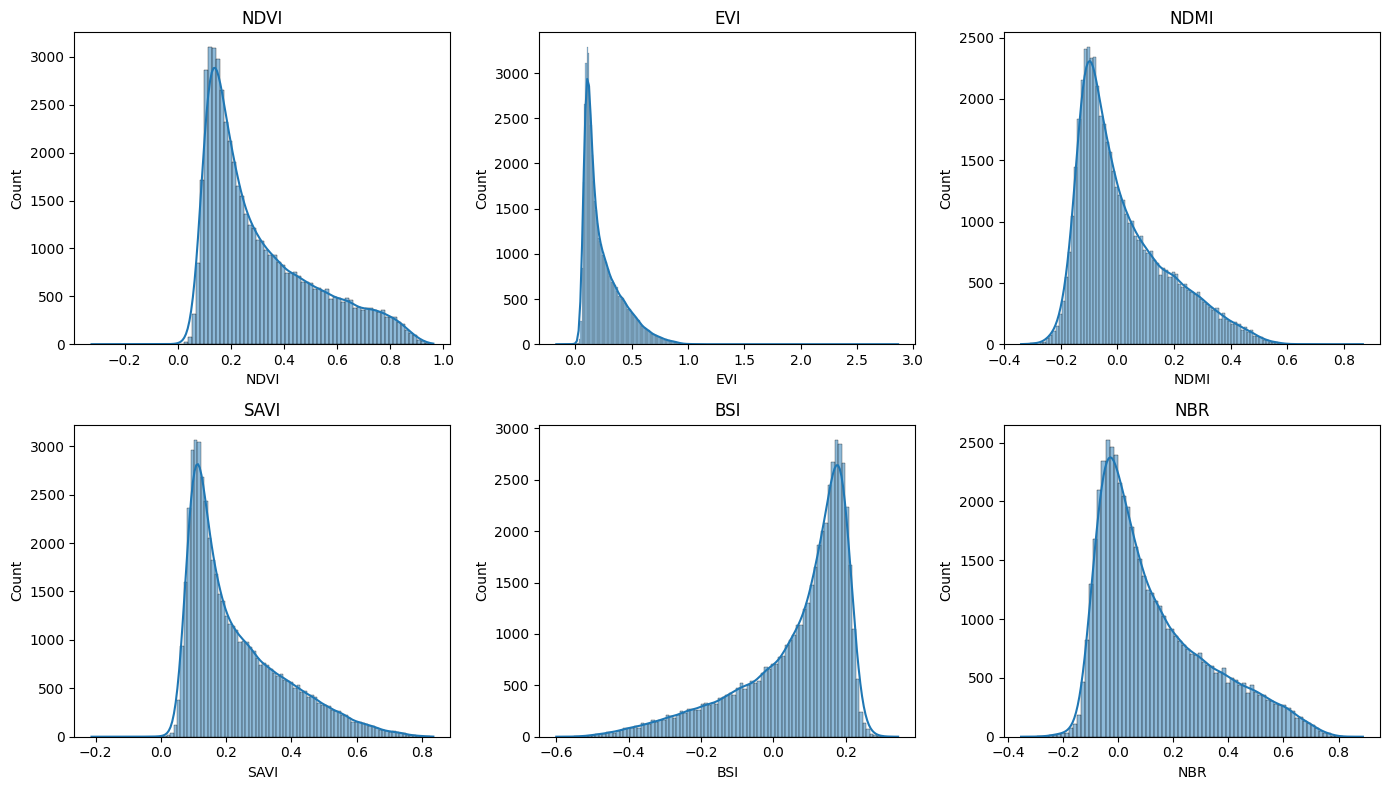

In [ ]:

# Visualize Feature Distributions

features = ['NDVI', 'EVI', 'NDMI', 'SAVI', 'BSI', 'NBR']

plt.figure(figsize=(14, 8))

for i, col in enumerate(features, 1):
    plt.subplot(2, 3, i)
    sns.histplot(df[col], kde=True)
    plt.title(col)

plt.tight_layout()
plt.show()

In [ ]:

# Create Target Variable

df['month_dt'] = pd.to_datetime(df['month'])

df = df.sort_values(['sample_id', 'month_dt'])

df['target_month'] = (
    df.groupby('sample_id')['month_dt'].shift(-1)
)

df['NDVI_next_month'] = (
    df.groupby('sample_id')['NDVI'].shift(-1)
)

# Keep consecutive months only
next_month = df['month_dt'] + pd.offsets.MonthBegin(1)

df = df[df['target_month'] == next_month].copy()

df['target_month'] = df['target_month'].dt.strftime('%Y-%m')

print("Target variable created successfully!")
print("Dataset Shape:", df.shape)

display(df.head())

Target variable created successfully!
Dataset Shape: (51880, 11)


,month,sample_id,NDVI,EVI,NDMI,SAVI,BSI,NBR,month_dt,target_month,NDVI_next_month
0,2018-01,0,0.401840,0.270593,0.157680,0.284075,-0.017439,0.325133,2018-01-01,2018-02,0.409121
500,2018-02,0,0.409121,0.196053,0.178351,0.229266,0.000213,0.331010,2018-02-01,2018-03,0.476376
941,2018-03,0,0.476376,0.348145,0.173175,0.348177,-0.053550,0.343226,2018-03-01,2018-04,0.282912
1441,2018-04,0,0.282912,0.205102,-0.017653,0.211011,0.107972,0.135900,2018-04-01,2018-05,0.113688
1941,2018-05,0,0.113688,0.090307,-0.078380,0.097285,0.176185,-0.029524,2018-05-01,2018-06,0.100046


In [ ]:



# Define Input Features and Target

features = ['NDVI', 'EVI', 'NDMI', 'SAVI', 'BSI', 'NBR']

X = df[features]
y = df['NDVI_next_month']

# Split data by time

months = sorted(df['month_dt'].unique())

split_index = int(len(months) * 0.8)
split_date = months[split_index]

# Convert target month to datetime
target_dates = pd.to_datetime(df['target_month'] + '-01')

# Correct time-based splitting
train_mask = target_dates < split_date
test_mask = target_dates >= split_date

X_train = X[train_mask]
X_test = X[test_mask]

y_train = y[train_mask]
y_test = y[test_mask]

# Normalize input features
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Display splitting results
print("Time-based splitting completed!")
print("Training samples:", len(X_train_scaled))
print("Testing samples:", len(X_test_scaled))
print("Total samples:", len(X_train_scaled) + len(X_test_scaled))
print("Input features:", len(features))
print("Target: NDVI_next_month")
print("Split date:", split_date)

Time-based splitting completed!
Training samples: 40880
Testing samples: 11000
Total samples: 51880
Input features: 6
Target: NDVI_next_month
Split date: 2024-12-01 00:00:00


In [ ]:


# Train ANN Model

model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(6,)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dense(32, activation='relu'),
    tf.keras.layers.Dense(1)
])

# Compile Model
model.compile(
    optimizer='adam',
    loss='mse',
    metrics=['mae']
)

# Train Model
history = model.fit(
    X_train_scaled,
    y_train,
    epochs=30,
    batch_size=32,
    validation_split=0.2,
    verbose=1
)

print("Final model training completed!")

Epoch 1/30
1022/1022 ━━━━━━━━━━━━━━━━━━━━ 7s 5ms/step - loss: 0.0237 - mae: 0.1075 - val_loss: 0.0204 - val_mae: 0.0985
Epoch 2/30
1022/1022 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0207 - mae: 0.1016 - val_loss: 0.0211 - val_mae: 0.1060
Epoch 3/30
1022/1022 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0205 - mae: 0.1006 - val_loss: 0.0202 - val_mae: 0.0969
Epoch 4/30
1022/1022 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0202 - mae: 0.1001 - val_loss: 0.0205 - val_mae: 0.0966
Epoch 5/30
1022/1022 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0200 - mae: 0.0996 - val_loss: 0.0201 - val_mae: 0.0969
Epoch 6/30
1022/1022 ━━━━━━━━━━━━━━━━━━━━ 3s 3ms/step - loss: 0.0199 - mae: 0.0991 - val_loss: 0.0198 - val_mae: 0.0985
Epoch 7/30
1022/1022 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0199 - mae: 0.0991 - val_loss: 0.0198 - val_mae: 0.0998
Epoch 8/30
1022/1022 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - loss: 0.0198 - mae: 0.0989 - val_loss: 0.0202 - val_mae: 0.0953
Epoch 9/30
1022/1022 ━━━━━━━━━━━━━━━━━━━

In [ ]:
# Evaluate the Model

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

# Predict test data
y_pred = model.predict(X_test_scaled).flatten()

# Calculate evaluation metrics
mae = mean_absolute_error(y_test, y_pred)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

r2 = r2_score(y_test, y_pred)

print("MODEL EVALUATION RESULTS")
print("========================")
print("MAE:", round(mae, 4))
print("RMSE:", round(rmse, 4))
print("R2 Score:", round(r2, 4))

344/344 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
MODEL EVALUATION RESULTS
MAE: 0.0859
RMSE: 0.1283
R2 Score: 0.585


In [ ]:

# Persistence Baseline Evaluation

baseline_pred = X_test['NDVI'].values

baseline_mae = mean_absolute_error(
    y_test, baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(y_test, baseline_pred)
)

baseline_r2 = r2_score(
    y_test, baseline_pred
)

print("BASELINE RESULTS")
print("=" * 35)
print("Baseline MAE:", round(baseline_mae, 4))
print("Baseline RMSE:", round(baseline_rmse, 4))
print("Baseline R2:", round(baseline_r2, 4))

print("\nANN vs BASELINE")
print("ANN MAE:", round(mae, 4))
print("ANN RMSE:", round(rmse, 4))
print("ANN R2:", round(r2, 4))

BASELINE RESULTS
Baseline MAE: 0.0874
Baseline RMSE: 0.1452
Baseline R2: 0.4683

ANN vs BASELINE
ANN MAE: 0.0859
ANN RMSE: 0.1283
ANN R2: 0.585


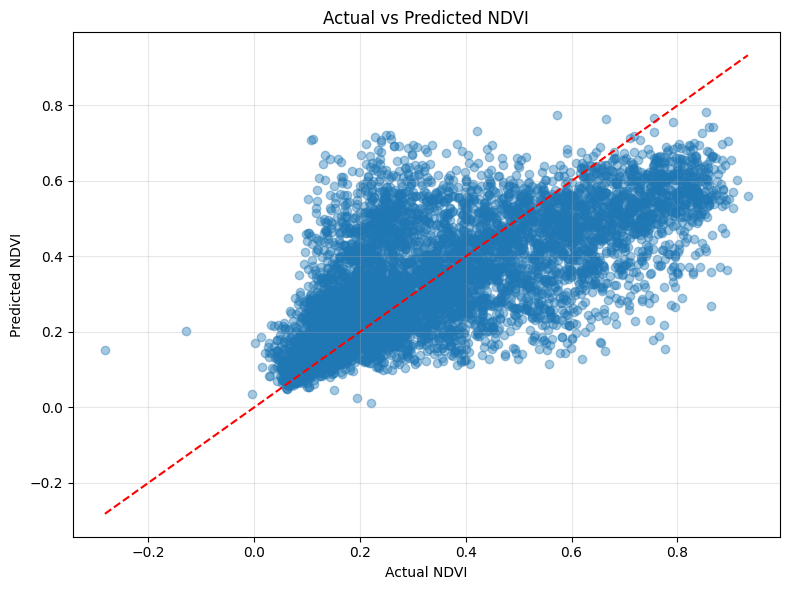

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.4
)

minimum = min(y_test.min(), y_pred.min())
maximum = max(y_test.max(), y_pred.max())

plt.plot(
    [minimum, maximum],
    [minimum, maximum],
    'r--'
)

plt.xlabel("Actual NDVI")
plt.ylabel("Predicted NDVI")
plt.title("Actual vs Predicted NDVI")

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

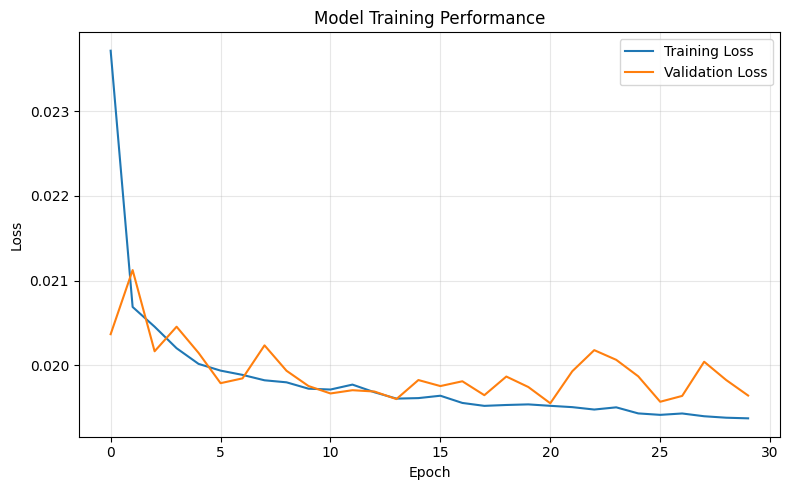

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['loss'],
    label='Training Loss'
)

plt.plot(
    history.history['val_loss'],
    label='Validation Loss'
)

plt.title("Model Training Performance")
plt.xlabel("Epoch")
plt.ylabel("Loss")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

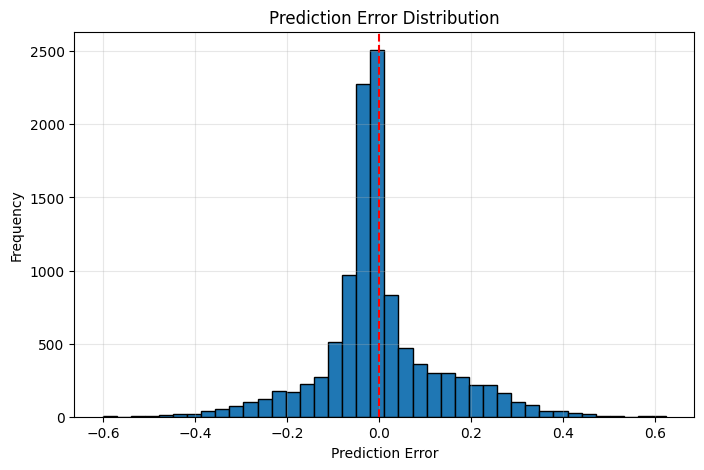

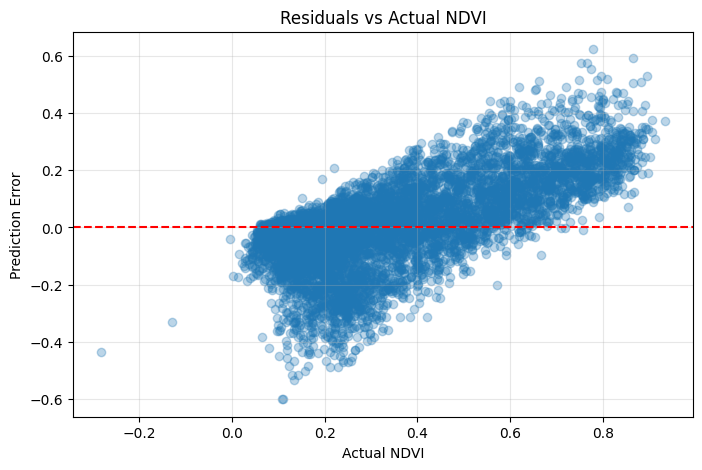

Mean Error: -0.0008
Error Std: 0.1283
MAE: 0.0859


In [ ]:

import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error

# Calculate prediction errors
errors = y_test - y_pred

# Residual distribution
plt.figure(figsize=(8, 5))
plt.hist(errors, bins=40, edgecolor='black')
plt.axvline(0, color='red', linestyle='--')

plt.title("Prediction Error Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.grid(alpha=0.3)
plt.show()

# Residuals versus actual NDVI
plt.figure(figsize=(8, 5))
plt.scatter(y_test, errors, alpha=0.3)
plt.axhline(0, color='red', linestyle='--')

plt.title("Residuals vs Actual NDVI")
plt.xlabel("Actual NDVI")
plt.ylabel("Prediction Error")
plt.grid(alpha=0.3)
plt.show()

print("Mean Error:", round(np.mean(errors), 4))
print("Error Std:", round(np.std(errors), 4))
print("MAE:", round(mean_absolute_error(y_test, y_pred), 4))

In [ ]:

import pandas as pd
import numpy as np

# Create evaluation dataframe
results = pd.DataFrame({
    "Actual": np.asarray(y_test).flatten(),
    "Predicted": np.asarray(y_pred).flatten()
})

results["Error"] = results["Actual"] - results["Predicted"]
results["Absolute_Error"] = results["Error"].abs()

# Divide NDVI into vegetation levels
results["NDVI_Level"] = pd.cut(
    results["Actual"],
    bins=[-1, 0.2, 0.4, 0.6, 1],
    labels=["Low", "Moderate", "High", "Very High"]
)

# Evaluate each level
evaluation = results.groupby(
    "NDVI_Level", observed=False
).agg(
    Samples=("Actual", "count"),
    MAE=("Absolute_Error", "mean"),
    Mean_Error=("Error", "mean"),
    RMSE=("Error", lambda x: np.sqrt(np.mean(x**2)))
)

print("PERFORMANCE BY NDVI LEVEL")
display(evaluation.round(4))

PERFORMANCE BY NDVI LEVEL


,Samples,MAE,Mean_Error,RMSE
NDVI_Level,,,,
Low,5471,0.0492,-0.0455,0.0813
Moderate,3054,0.0890,-0.0396,0.1275
High,1274,0.1180,0.0854,0.1492
Very High,1201,0.2111,0.2103,0.2361
